In [13]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import warnings
warnings.filterwarnings('ignore')


In [14]:
# Load Dataset

df = pd.read_csv("/content/Data_file - data_file Early_Disease_Detection.csv")
df.head()

,date,country,id,active,age,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,occupation,smoke,weight,disease
0,03-05-2021,Indonesia,0,1,18393,0,110,80,1,2,1,168,Architect,0,62.0,0
1,05-08-2021,Malaysia,1,1,20228,0,140,90,3,1,1,156,Accountant,0,85.0,1
2,13-11-2022,Indonesia,2,0,18857,0,130,70,3,1,1,165,Chef,0,64.0,1
3,31-10-2018,Singapore,3,1,17623,0,150,100,1,2,1,169,Lawyer,0,82.0,1
4,25-09-2020,Singapore,4,0,17474,0,100,60,1,1,1,156,Architect,0,56.0,0


In [15]:
# Initial Data Exploration

df.describe()

,id,active,age,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,weight,disease
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,0.803729,19468.865814,0.053771,128.817286,96.630414,1.366871,1.349571,1.226457,164.359229,0.088129,74.205690,0.499700
std,28851.302323,0.397179,2467.251667,0.225568,154.011419,188.472530,0.680250,0.476838,0.572270,8.210126,0.283484,14.395757,0.500003
min,0.000000,0.000000,10798.000000,0.000000,-150.000000,-70.000000,1.000000,1.000000,1.000000,55.000000,0.000000,10.000000,0.000000
25%,25006.750000,1.000000,17664.000000,0.000000,120.000000,80.000000,1.000000,1.000000,1.000000,159.000000,0.000000,65.000000,0.000000
50%,50001.500000,1.000000,19703.000000,0.000000,120.000000,80.000000,1.000000,1.000000,1.000000,165.000000,0.000000,72.000000,0.000000
75%,74889.250000,1.000000,21327.000000,0.000000,140.000000,90.000000,2.000000,2.000000,1.000000,170.000000,0.000000,82.000000,1.000000
max,99999.000000,1.000000,23713.000000,1.000000,16020.000000,11000.000000,3.000000,2.000000,3.000000,250.000000,1.000000,200.000000,1.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         70000 non-null  object 
 1   country      70000 non-null  object 
 2   id           70000 non-null  int64  
 3   active       70000 non-null  int64  
 4   age          70000 non-null  int64  
 5   alco         70000 non-null  int64  
 6   ap_hi        70000 non-null  int64  
 7   ap_lo        70000 non-null  int64  
 8   cholesterol  70000 non-null  int64  
 9   gender       70000 non-null  int64  
 10  gluc         70000 non-null  int64  
 11  height       70000 non-null  int64  
 12  occupation   70000 non-null  object 
 13  smoke        70000 non-null  int64  
 14  weight       70000 non-null  float64
 15  disease      70000 non-null  int64  
dtypes: float64(1), int64(12), object(3)
memory usage: 8.5+ MB


<Axes: title={'center': 'Target Distribution (disease)'}, xlabel='disease'>

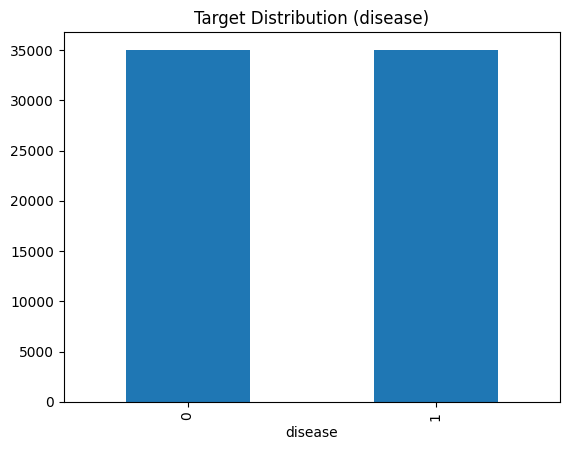

In [4]:
df.info()
df['disease'].value_counts().plot(kind='bar', title='Target Distribution (disease)')


In [33]:
df.shape
print(df.columns)

Index(['active', 'age', 'alco', 'ap_hi', 'ap_lo', 'cholesterol', 'gender',
       'gluc', 'height', 'smoke', 'weight', 'disease', 'occupation_Architect',
       'occupation_Chef', 'occupation_Doctor', 'occupation_Engineer',
       'occupation_Lawyer', 'occupation_Nurse', 'occupation_Others',
       'occupation_Teacher', 'country_Indonesia', 'country_Malaysia',
       'country_Singapore'],
      dtype='object')


In [16]:
# Data Claning and Feature Engineering


# Convert age from days to years
df['age'] = (df['age'] / 365).astype(int)

# Drop irrelevant columns
df.drop(columns=['id', 'date'], inplace=True)

# Encode categorical features
df['gender'] = df['gender'].map({'male': 1, 'female': 0})

# One-hot encoding for occupation and country if needed
df = pd.get_dummies(df, columns=['occupation', 'country'], drop_first=True)

# Check and handle missing values
df.isnull().sum()

# Outlier handling (example for blood pressure)
df = df[(df['ap_hi'] < 250) & (df['ap_lo'] < 200)]


In [6]:
# Feature Scaling

scaler = StandardScaler()
numerical_features = ['age', 'ap_hi', 'ap_lo', 'weight', 'height']

df[numerical_features] = scaler.fit_transform(df[numerical_features])


In [7]:
# Train-Test Split

X = df.drop('disease', axis=1)
y = df['disease']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [8]:
# Model Training and Evaluation Function

def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred))


In [17]:
# Train Models
# Logistic Regression

from sklearn.impute import SimpleImputer

# Use mean, median, or most_frequent depending on the data
imputer = SimpleImputer(strategy='mean')  # or 'median', 'most_frequent'
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Train model with imputed data
lr = LogisticRegression()
lr.fit(X_train_imputed, y_train)
print("Logistic Regression Results:")
evaluate_model(lr, X_test_imputed, y_test)


Logistic Regression Results:
Accuracy: 0.7236632372119982
Precision: 0.7479858201740252
Recall: 0.6735345327916424
F1 Score: 0.7088105054206749
[[5346 1564]
 [2250 4642]]
              precision    recall  f1-score   support

           0       0.70      0.77      0.74      6910
           1       0.75      0.67      0.71      6892

    accuracy                           0.72     13802
   macro avg       0.73      0.72      0.72     13802
weighted avg       0.73      0.72      0.72     13802



In [19]:
# Decision Tree

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
print("Decision Tree Results:")
evaluate_model(dt, X_test, y_test)


Decision Tree Results:
Accuracy: 0.6346181712795247
Precision: 0.6324308838275319
Recall: 0.6405977945443994
F1 Score: 0.6364881424349456
[[4344 2566]
 [2477 4415]]
              precision    recall  f1-score   support

           0       0.64      0.63      0.63      6910
           1       0.63      0.64      0.64      6892

    accuracy                           0.63     13802
   macro avg       0.63      0.63      0.63     13802
weighted avg       0.63      0.63      0.63     13802



In [18]:
# Random Forest

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
print("Random Forest Results:")
evaluate_model(rf, X_test, y_test)

Random Forest Results:
Accuracy: 0.7174322561947544
Precision: 0.7245571900330231
Recall: 0.7003772489843296
F1 Score: 0.7122620628596724
[[5075 1835]
 [2065 4827]]
              precision    recall  f1-score   support

           0       0.71      0.73      0.72      6910
           1       0.72      0.70      0.71      6892

    accuracy                           0.72     13802
   macro avg       0.72      0.72      0.72     13802
weighted avg       0.72      0.72      0.72     13802



In [ ]:
# Support Vector Machine

from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

# Pipeline: impute missing values, then fit SVM
svm = make_pipeline(SimpleImputer(strategy='mean'), SVC(probability=True))

# Fit and evaluate
svm.fit(X_train, y_train)
print("SVM Results:")
evaluate_model(svm, X_test, y_test)

In [24]:
import pickle

with open("heart_disease_model.pkl", "wb") as file:
    pickle.dump(rf, file)  # Replace `rf` with your trained model variable


In [26]:
!pip install streamlit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 4.7 MB/s eta 0:00:00


In [37]:
# Redine dataset and split

import pandas as pd
from sklearn.model_selection import train_test_split

# Load the data
df = pd.read_csv("Data_file - data_file Early_Disease_Detection.csv")

# Basic cleaning
df['age'] = (df['age'] / 365).astype(int)
df['gender'] = df['gender'].map({1: 1, 2: 0})
df.drop(columns=['id', 'date'], inplace=True)
df.dropna(inplace=True)
df = df[(df['ap_hi'] > 60) & (df['ap_hi'] < 250)]
df = df[(df['ap_lo'] > 30) & (df['ap_lo'] < 200)]

# Define features and target
X = df.drop('disease', axis=1)
y = df['disease']


In [38]:
# Build the pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
import pickle

# Feature type separation
num_features = ['age', 'ap_hi', 'ap_lo', 'weight', 'height']
cat_features = ['cholesterol', 'gluc', 'smoke', 'alco', 'active', 'gender', 'occupation', 'country']

# Column transformer for preprocessing
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])

# Final pipeline: preprocessing + model
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Fit on full data
pipeline.fit(X, y)

# Save the entire pipeline
with open("heart_disease_pipeline.pkl", "wb") as f:
    pickle.dump(pipeline, f)


In [39]:
# app.py

import streamlit as st
import pickle
import pandas as pd

# Load pipeline
with open("heart_disease_pipeline.pkl", "rb") as f:
    model = pickle.load(f)

st.title("Heart Disease Predictor")

# Collect user input
user_input = {
    "age": st.number_input("Age (years)", 1, 120, 30),
    "ap_hi": st.number_input("Systolic BP", 80, 250, 120),
    "ap_lo": st.number_input("Diastolic BP", 40, 200, 80),
    "weight": st.number_input("Weight (kg)", 30.0, 200.0, 70.0),
    "height": st.number_input("Height (cm)", 100, 250, 170),
    "cholesterol": st.selectbox("Cholesterol", [1, 2, 3]),
    "gluc": st.selectbox("Glucose", [1, 2, 3]),
    "smoke": st.selectbox("Smokes?", [0, 1]),
    "alco": st.selectbox("Alcohol intake?", [0, 1]),
    "active": st.selectbox("Physically active?", [0, 1]),
    "gender": st.selectbox("Gender", ["Male", "Female"]),
    "occupation": st.selectbox("Occupation", ['Architect', 'Accountant', 'Chef', 'Lawyer']),
    "country": st.selectbox("Country", ['Indonesia', 'Malaysia', 'Singapore'])
}

# Convert input to dataframe
input_df = pd.DataFrame([user_input])

# Map gender to 1/0
input_df["gender"] = input_df["gender"].map({"Male": 1, "Female": 0})

# Predict
if st.button("Predict"):
    prediction = model.predict(input_df)[0]
    st.subheader("Prediction:")
    st.write("High Risk of Heart Disease" if prediction == 1 else "Low Risk of Heart Disease")


In [40]:
!streamlit run app.py




  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.13.248.172:8501

  Stopping...
^C
